In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress, norm, percentileofscore
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import pyreadr
import statistics as stats
import math
from tabulate import tabulate
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.patches as patches
import pyBigWig
import re

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

1
1


In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [5]:
# cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
# n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [5]:
n_cycles, n_comps, n_DHSs = mixture_all_cycles.shape

In [6]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [7]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs

In [8]:
removed_DHS_identifiers = np.array(DHS_metadata.loc[removed_DHS_inds]['identifier'])

In [9]:
removed_biosample_ln = np.array(biosample_df.loc[removed_biosample_inds]['Altius Library ID'])
removed_biosample_ln_stripped = np.array([])
for ln in removed_biosample_ln:
    if ln[-1].isalpha():
        removed_biosample_ln_stripped = np.append(removed_biosample_ln_stripped, ln[:-1])
    else:
        removed_biosample_ln_stripped = np.append(removed_biosample_ln_stripped, ln)

In [10]:
identifier2chunk = {}
chunk2identifier = {}
f = open("/home/meuleman/projects/ENCODE3/WM20180608_construct_masterlist_733samples/masterlist_DHSs_733samples_WM20180608_all_chunkIDs2indexIDs.txt", "r")
for line in f:
    line = line.strip().split('\t')
    identifier2chunk[line[0]] = line[1]
    chunk2identifier[line[1]] = line[0]
f.close()

In [11]:
#finding the chunks of each removed DHS
removed_DHS_chunks = np.array([])
for identifier in removed_DHS_identifiers:
    removed_DHS_chunks = np.append(removed_DHS_chunks, identifier2chunk[identifier])

In [16]:
# #for each removed call, finding the biosamples that contributed to the DHS and where the peak signal is
# removed_DHS_calls = []
# removed_DHS_original_peaks = []
# for chunk in removed_DHS_chunks:
#     chunk_info = []
#     core_chunk = chunk.split('_')[0]
#     core_bed = open("/net/seq/data/projects/ENCODE3_publications/erynes/ENCODEpaper2017/SubsetOf733/masterLists/workdir/peaks_all/"+core_chunk+".bed", "r")
#     for line in core_bed:
#         line = line.strip().split('\t')
#         if line[-1]==chunk:
#             chunk_info.append(line)
#     chunk_info = np.array(chunk_info)
#     removed_DHS_calls.append(chunk_info)
#     removed_DHS_original_peaks.append(np.median(chunk_info[:, 6].astype(int)))
#     core_bed.close()
# removed_DHS_original_peaks = np.array(removed_DHS_original_peaks).astype(int)

In [17]:
# pickle_out = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'wb')
# pickle.dump(removed_DHS_calls, pickle_out)
# pickle_out.close()

In [18]:
# pickle_out = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'wb')
# pickle.dump(removed_DHS_original_peaks, pickle_out)
# pickle_out.close()

In [12]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'rb')
removed_DHS_calls=pickle.load(pickle_in)

In [13]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'rb')
removed_DHS_original_peaks=pickle.load(pickle_in)

In [14]:
DHS_identifiers = np.array(DHS_metadata['identifier'])

In [15]:
identifier2ind = {}
for i in range(len(DHS_identifiers)):
    identifier2ind[DHS_identifiers[i]] = i

In [16]:
#distances from each removed call peak to consesus peak
removed_peak_distance_from_consensus_all = []
max_distance_from_consensus_all = []
removed_peak_order_from_consensus_all = []
number_of_unique_distances_all = []
removed_peak_distance_percentile = []
all_call_distance_percentiles_from_removed_DHSs = []
confusion = np.zeros((733, 2, 2), dtype=int)
for peak_location, chunk_info, removed_ln in zip(removed_DHS_original_peaks, 
                                                 removed_DHS_calls, 
                                                 removed_biosample_ln_stripped):
    #start and end of core region
    core_95 = np.ceil(np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5])).astype(int)
    core_start = core_95[0]
    core_end = core_95[1]
#     DHS_ind = np.where(DHS_identifiers==chunk2identifier[chunk_info[0, 7]])[0][0]
    DHS_ind = identifier2ind[chunk2identifier[chunk_info[0, 7]]]
    DHS_start = int(DHS_metadata.loc[DHS_ind]['start'])
    DHS_end = int(DHS_metadata.loc[DHS_ind]['end'])
    if core_start < DHS_start:
        core_start = DHS_start
    if core_end > DHS_end:
        core_end = DHS_end
    
    #all calls distance from consensus
    all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
    
    #removed biosample local ind
    removed_inds = np.where(chunk_info==removed_ln)[0]
    
    for removed_ind in removed_inds:
        #distance of removed call from peak
        removed_peak_distance_from_consensus = np.abs(chunk_info[removed_ind, 6].astype(int) - peak_location)
        removed_peak_distance_from_consensus_all.append(removed_peak_distance_from_consensus)
        #max distance from all calls to consensus peak
        max_distance_from_consensus = np.max(np.abs(chunk_info[:, 6].astype(int) - peak_location))
        max_distance_from_consensus_all.append(max_distance_from_consensus)
        #finding order of distances of removed call (0 is closest to consensus, the larger the number, 
        #the further away)
        unique_distances = np.unique(np.abs(chunk_info[:, 6].astype(int) - peak_location))
        removed_peak_order_from_consensus = np.where(unique_distances==removed_peak_distance_from_consensus)[0][0]
        removed_peak_order_from_consensus_all.append(removed_peak_order_from_consensus)
        #number of unique distances
        number_of_unique_distances = len(unique_distances)
        number_of_unique_distances_all.append(number_of_unique_distances)
        #percentile of distance
#         all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
        percentile = percentileofscore(all_distances, removed_peak_distance_from_consensus)
        removed_peak_distance_percentile.append(percentile)
#         #random removals
#         DHS_inds = np.where(DHS_identifiers==chunk2identifier[chunk_info[0, 7]])[0][0]
#         core_start = np.array(DHS_metadata.loc[[DHS_inds]]['core_start']).astype(int)[0]
#         core_end = np.array(DHS_metadata.loc[[DHS_inds]]['core_end']).astype(int)[0]
#         core_95 = np.ceil(np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5])).astype(int)
#         core_start = core_95[0]
#         core_end = core_95[1]
        
#         removed_peak = chunk_info[removed_ind, 6].astype(int)
#         if ((removed_peak < core_start) | (removed_peak > core_end)):
#             con_row = 0
#         else:
#             con_row = 1
#         random_call = random.randrange(len(chunk_info))
#         random_peak = chunk_info[random_call, 6].astype(int)
#         if ((random_peak < core_start) | (random_peak > core_end)):
#             con_col = 0
#         else:
#             con_col = 1
#         contingency[len(chunk_info)-1, con_row, con_col]+=1
        
    for call in range(len(chunk_info)):
        call_distance = np.abs(chunk_info[call, 6].astype(int) - peak_location)
        call_percentile = percentileofscore(all_distances, call_distance)
        all_call_distance_percentiles_from_removed_DHSs.append(call_percentile)
        
        call_peak = chunk_info[call, 6].astype(int)
        if ((call_peak < core_start) | (call_peak > core_end)): #outside core or not
            con_col = 0
        else:
            con_col = 1

        if call in removed_inds: #removed or not
            con_row = 0
        else:
            con_row = 1
        confusion[len(chunk_info)-1, con_row, con_col]+=1
            
    
removed_peak_distance_from_consensus_all = np.array(removed_peak_distance_from_consensus_all)
max_distance_from_consensus_all = np.array(max_distance_from_consensus_all)
number_of_unique_distances_all = np.array(number_of_unique_distances_all)
removed_peak_order_from_consensus_all = np.array(removed_peak_order_from_consensus_all)
removed_peak_distance_percentile = np.array(removed_peak_distance_percentile)
all_call_distance_percentiles_from_removed_DHSs = np.array(all_call_distance_percentiles_from_removed_DHSs)

In [17]:
confusion_all = np.sum(confusion, axis=0)
print('precision = ' + str(confusion_all[0, 0] / (confusion_all[0, 0] + confusion_all[0, 1])))
print('recall = ' + str(confusion_all[0, 0] / (confusion_all[0, 0] + confusion_all[1, 0])))
confusion_all

precision = 0.23053746289157695
recall = 0.10821547420965058


array([[   5203,   17366],
       [  42877, 1104806]])

In [18]:
precision_733 = confusion[:, 0, 0] / (confusion[:, 0, 0] + confusion[:, 0, 1])
recall_733 = confusion[:, 0, 0] / (confusion[:, 0, 0] + confusion[:, 1, 0])

/tmp/ipykernel_80431/1096275.py:1: RuntimeWarning: invalid value encountered in true_divide
  precision_733 = confusion[:, 0, 0] / (confusion[:, 0, 0] + confusion[:, 0, 1])
/tmp/ipykernel_80431/1096275.py:2: RuntimeWarning: invalid value encountered in true_divide
  recall_733 = confusion[:, 0, 0] / (confusion[:, 0, 0] + confusion[:, 1, 0])


/tmp/ipykernel_80431/1202558387.py:12: RuntimeWarning: invalid value encountered in true_divide
  axes[1].hist(removed_peak_distance_from_consensus_all/max_distance_from_consensus_all, bins=40, alpha=0.7)


Text(0.5, 1.02, 'Summit of Removed Calls Are Distant from DHS Consensus Summit')

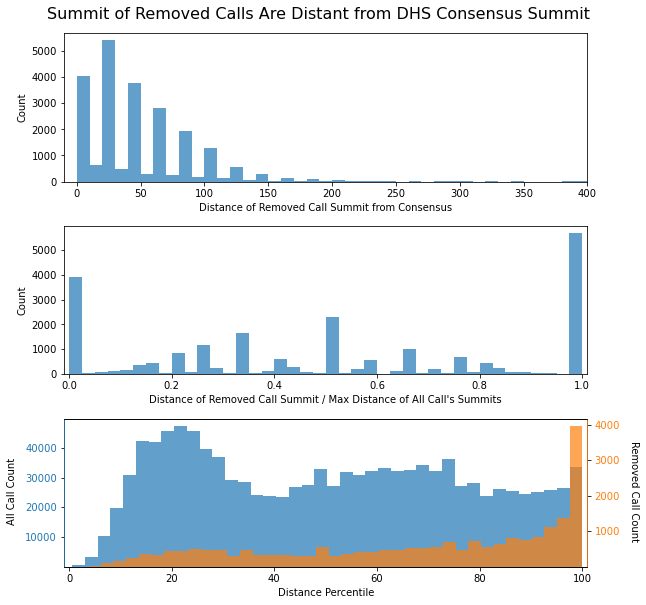

In [19]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8,8))
fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.3)
fig.patch.set_facecolor('white')

axes[0].hist(removed_peak_distance_from_consensus_all[removed_peak_distance_from_consensus_all<=400], bins=40, alpha=0.7)
axes[0].set_xlim([-10, 400])
axes[0].set_xlabel('Distance of Removed Call Summit from Consensus')
axes[0].set_ylabel('Count')
# axes[0].set_yscale('log')

axes[1].hist(removed_peak_distance_from_consensus_all/max_distance_from_consensus_all, bins=40, alpha=0.7)
axes[1].set_xlim([-.01, 1.01])
axes[1].set_xlabel('Distance of Removed Call Summit / Max Distance of All Call\'s Summits')
axes[1].set_ylabel('Count')
# axes[1].set_yscale('log')


axes[2].hist(all_call_distance_percentiles_from_removed_DHSs, bins=40, alpha=0.7)
axes[2].set_xlim([-1, 101])
ax2_twin = axes[2].twinx()
ax2_twin.hist(removed_peak_distance_percentile, color='#ff7f0e', bins=40, alpha=0.7)


axes[2].set_xlabel('Distance Percentile')
# axes[2].set_ylabel('All Call Count')
# ax2_twin.set_ylabel('Removed Call Count', rotation=270)

axes[2].set_yticks([10000, 20000, 30000, 40000])
axes[2].set_yticklabels([10000, 20000, 30000, 40000], c='#1f77b4')
ax2_twin.set_yticks([1000, 2000, 3000, 4000])
ax2_twin.set_yticklabels([1000, 2000, 3000, 4000], c='#ff7f0e')
fig.text(-0.04, 0.18, 'All Call Count', va='center', rotation=90, fontsize=10)
fig.text(1.04, 0.18, 'Removed Call Count', va='center', rotation=270, fontsize=10)
ax2_twin.spines['left'].set_color('#1f77b4')
ax2_twin.spines['right'].set_color('#ff7f0e')
# axes[2].set_yscale('log')

plt.suptitle('Summit of Removed Calls Are Distant from DHS Consensus Summit', fontsize=16, x=0.5, y=1.02)

In [17]:
# biosample_pvals = []
# biosample_ratios = []
# for conting in contingency:
#     if np.min(conting) < 25:
#         pval = mcnemar(conting, exact=True).pvalue
#     else:
#         pval = mcnemar(conting, exact=False, correction=True).pvalue
#     biosample_pvals.append(pval)
#     ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
#     biosample_ratios.append(ratio)
# biosample_pvals = np.array(biosample_pvals)
# biosample_ratios = np.array(biosample_ratios)

/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: invalid value encountered in long_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: invalid value encountered in double_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: divide by zero encountered in long_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))


/tmp/ipykernel_125309/2123723629.py:16: RuntimeWarning: divide by zero encountered in log2
  np.log2(biosample_ratios),


Text(0.5, 1.02, 'Significance of Flip Based vs Random Removal of Calls\nOutside DHS Core Region by Number of Peaks in DHS')

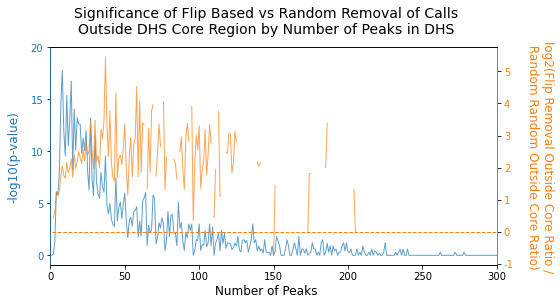

In [293]:
# fig, ax = plt.subplots(figsize=(8,4))
# fig.patch.set_facecolor('white')
# # fig.tight_layout()

# ax.plot(np.arange(1, 734), 
#         -np.log10(biosample_pvals),
#         alpha=0.7, 
#         linewidth=1)
# ax.set_yticks([0, 5, 10, 15, 20])
# ax.set_yticklabels([0, 5, 10, 15, 20], c='#1f77b4')
# ax.set_xlim([0, 300])

# ax2 = ax.twinx()
# ax2.plot(np.arange(1, 734), np.zeros((733)), color='#ff7f0e', linestyle='--', linewidth=1)
# ax2.plot(np.arange(1, 734), 
#          np.log2(biosample_ratios), 
#          color='#ff7f0e',
#          alpha=0.7,
#          linewidth=1)
# ax2.set_yticks([-1, 0, 1, 2, 3, 4, 5])
# ax2.set_yticklabels([-1, 0, 1, 2, 3, 4, 5], c='#ff7f0e')
# ax2.spines['left'].set_color('#1f77b4')
# ax2.spines['right'].set_color('#ff7f0e')
    
    
# fig.text(0.05, 0.5, '-log10(p-value)', va='center', rotation='vertical', fontsize=12, color='#1f77b4')
# fig.text(0.95, 0.5, 'log2(Flip Removal Outside Core Ratio /\n Random Random Outside Core Ratio)', va='center', rotation=270, fontsize=12, color='#ff7f0e')
# fig.text(0.5, 0.02, 'Number of Peaks', ha='center', fontsize=12)
# plt.suptitle('Significance of Flip Based vs Random Removal of Calls\nOutside DHS Core Region by Number of Peaks in DHS', fontsize=14, x=0.5, y=1.02)

In [16]:
#distances from each removed call peak to consesus peak



#to look at panel 2 0s only



removed_peak_distance_from_consensus_all = []
max_distance_from_consensus_all = []
removed_peak_order_from_consensus_all = []
number_of_unique_distances_all = []
removed_peak_distance_percentile = []
for peak_location, chunk_info, removed_ln in zip(removed_DHS_original_peaks, 
                                                 removed_DHS_calls, 
                                                 removed_biosample_ln_stripped):
#     print(peak_location, chunk_info.shape, removed_ln)
    #removed biosample local ind
    removed_ind = np.where(chunk_info==removed_ln)[0][0]
    #distance of removed call from peak
    removed_peak_distance_from_consensus = np.abs(chunk_info[removed_ind, 6].astype(int) - peak_location)
    removed_peak_distance_from_consensus_all.append(removed_peak_distance_from_consensus)
    #max distance from all calls to consensus peak
    max_distance_from_consensus = np.max(np.abs(chunk_info[:, 6].astype(int) - peak_location))
    max_distance_from_consensus_all.append(max_distance_from_consensus)
    #finding order of distances of removed call (0 is closest to consensus, the larger the number, 
    #the further away)
    unique_distances = np.unique(np.abs(chunk_info[:, 6].astype(int) - peak_location))
    removed_peak_order_from_consensus = np.where(unique_distances==removed_peak_distance_from_consensus)[0][0]
    removed_peak_order_from_consensus_all.append(removed_peak_order_from_consensus)
    #number of unique distances
    number_of_unique_distances = len(unique_distances)
    number_of_unique_distances_all.append(number_of_unique_distances)
    #percentile of distance
    all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
    percentile = percentileofscore(all_distances, removed_peak_distance_from_consensus)
    removed_peak_distance_percentile.append(percentile)
    
removed_peak_distance_from_consensus_all = np.array(removed_peak_distance_from_consensus_all)
max_distance_from_consensus_all = np.array(max_distance_from_consensus_all)
number_of_unique_distances_all = np.array(number_of_unique_distances_all)
removed_peak_order_from_consensus_all = np.array(removed_peak_order_from_consensus_all)
removed_peak_distance_percentile = np.array(removed_peak_distance_percentile)

In [44]:
panel2_0_removals = np.where((removed_peak_distance_from_consensus_all/max_distance_from_consensus_all)==0)[0]

/tmp/ipykernel_125309/3567242376.py:1: RuntimeWarning: invalid value encountered in true_divide
  panel2_0_removals = np.where((removed_peak_distance_from_consensus_all/max_distance_from_consensus_all)==0)[0]


In [45]:
print(np.mean(max_distance_from_consensus_all[panel2_0_removals]))
print(np.mean(max_distance_from_consensus_all))

68.08586900464157
87.73879732739421


In [46]:
print(np.mean(removed_peak_distance_from_consensus_all[panel2_0_removals]))
print(np.mean(removed_peak_distance_from_consensus_all))

0.0
44.372783964365254


In [58]:
print(np.mean(biosample_df.loc[removed_biosample_inds[panel2_0_removals]]['DCC SPOT score']))
print(np.mean(biosample_df.loc[removed_biosample_inds]['DCC SPOT score']))

0.4903005930892176
0.48201417371937677


In [60]:
print(np.mean(biosample_df.loc[removed_biosample_inds[panel2_0_removals]]['Reads used']))
print(np.mean(biosample_df.loc[removed_biosample_inds]['Reads used']))

110922450.96879835
120458698.62988864


In [51]:
#for panel 2 0s, average number of biosamples
panel2_0s_numsamples = np.array(DHS_metadata.loc[removed_DHS_inds[panel2_0_removals]]['numsamples']).astype(int)
print(np.mean(panel2_0s_numsamples))
#average number of biosamples in all DHSs
print(np.mean(np.array(DHS_metadata.loc[removed_DHS_inds]['numsamples']).astype(int)))

48.40510572460031
51.90971046770601


In [50]:
#for panel 2 0s, mean signal
panel2_0s_numsamples = np.array(DHS_metadata.loc[removed_DHS_inds[panel2_0_removals]]['mean_signal']).astype(float)
print(np.mean(panel2_0s_numsamples))
#mean signal in all DHSs
print(np.mean(np.array(DHS_metadata.loc[removed_DHS_inds]['mean_signal']).astype(float)))

0.934324236691378
1.0245196365301286


In [20]:
#totalling removed biosamples for each chunk
removed_ln_from_each_chunk = {}
unique_removed_DHS_calls = []
for chunk_info, removed_ln in zip(removed_DHS_calls, 
                                  removed_biosample_ln_stripped):
    chunk = chunk_info[0][-1]
    if chunk not in removed_ln_from_each_chunk:
        removed_ln_from_each_chunk[chunk] = np.array([removed_ln])
        unique_removed_DHS_calls.append(chunk_info)
    else:
        removed_ln_from_each_chunk[chunk] = np.append(removed_ln_from_each_chunk[chunk], [removed_ln])

In [29]:
len(unique_removed_DHS_calls)

20474

In [21]:
#for each unique DHS with a removed call, find consensus peak and range of peaks before and after flipping
#also finding max distance of removed call in DHS
original_DHS_peak_all = []
new_DHS_peak_all = []
original_DHS_peak_range_all = []
new_DHS_peak_range_all = []
max_removed_distance_all = []
corresponding_DHS_identifiers_for_each_unique_chunks = []
original_unlimited_core_width_all = []
new_unlimited_core_width_all = []
ordered_inds_removed_call_DHSs = []
for chunk_info in unique_removed_DHS_calls:
    chunk = chunk_info[0][-1]
    ordered_inds_removed_call_DHSs.append(identifier2ind[chunk2identifier[chunk]])
    #start and end of core region
    core_95 = np.ceil(np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5])).astype(int)
    original_core_start = core_95[0]
    original_core_end = core_95[1]
    
    corresponding_DHS_identifiers_for_each_unique_chunks.append(chunk2identifier[chunk])
    removed_lns = removed_ln_from_each_chunk[chunk]
    original_peak = np.median(chunk_info[:, 6].astype(int))
    original_range = np.max(chunk_info[:, 6].astype(int)) - np.min(chunk_info[:, 6].astype(int))
    max_distance = 0
    for ln in removed_lns:
        max_distance = np.max([max_distance, 
                               np.abs(chunk_info[chunk_info[:, 3]==ln][0][6].astype(int) - original_peak)])
        chunk_info = chunk_info[chunk_info[:, 3]!=ln]
    #new core region
    core_95 = np.ceil(np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5])).astype(int)
    new_core_start = core_95[0]
    new_core_end = core_95[1]
    original_unlimited_core_width = original_core_end - original_core_start
    original_unlimited_core_width_all.append(original_unlimited_core_width)
    new_unlimited_core_width = new_core_end - new_core_start
    new_unlimited_core_width_all.append(new_unlimited_core_width)
    
    new_peak = np.median(chunk_info[:, 6].astype(int))
    new_range = np.max(chunk_info[:, 6].astype(int)) - np.min(chunk_info[:, 6].astype(int))
    original_DHS_peak_all.append(original_peak)
    new_DHS_peak_all.append(new_peak)
    original_DHS_peak_range_all.append(original_range)
    new_DHS_peak_range_all.append(new_range)
    max_removed_distance_all.append(max_distance)
    
ordered_inds_removed_call_DHSs = np.array(ordered_inds_removed_call_DHSs)
original_DHS_peak_all = np.array(original_DHS_peak_all)
new_DHS_peak_all = np.array(new_DHS_peak_all)
original_DHS_peak_range_all = np.array(original_DHS_peak_range_all)
new_DHS_peak_range_all = np.array(new_DHS_peak_range_all)
max_removed_distance_all = np.array(max_removed_distance_all)
corresponding_DHS_identifiers_for_each_unique_chunks = np.array(corresponding_DHS_identifiers_for_each_unique_chunks)
original_unlimited_core_width_all = np.array(original_unlimited_core_width_all)
new_unlimited_core_width_all = np.array(new_unlimited_core_width_all)

In [202]:
#calculating start and end positions

chunk_info = unique_removed_DHS_calls[0]
chunk_starts = chunk_info[:, 1].astype(int)
chunk_ends = chunk_info[:, 2].astype(int)
min_start = np.min(chunk_starts)
max_end = np.max(chunk_ends)
fwhm_pyramid = np.zeros(max_end-min_start, dtype=int)
for i in range(len(chunk_info)):
    fwhm_pyramid[(chunk_starts[i] - min_start):(chunk_ends[i] - min_start)] += 1
max_val = np.max(fwhm_pyramid)
half_max = np.ceil(max_val/2).astype(int)

#finding start
min_maxposition = np.where(fwhm_pyramid==max_val)[0][0]
step_val = max_val
position = min_maxposition
while step_val >= half_max:
    position -= 1
    step_val = fwhm_pyramid[position]
start = position + 1 + min_start

#finding_end
max_maxposition = np.where(fwhm_pyramid==max_val)[0][-1]
step_val = max_val
position = max_maxposition
while step_val >= half_max:
    position += 1
    step_val = fwhm_pyramid[position]
end = position - 1 + min_start

In [203]:
DHS_metadata.loc[[identifier2ind[chunk2identifier[chunk_info[0, -1]]]]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
61585,chr1,36257489,36257659,1.231066,0.714001,72,36257570,36257550,36257610,Primitive / embryonic


In [204]:
end-36257659

-5

In [205]:
half_max, max_val

(35, 70)

In [206]:
start, end

(36257491, 36257654)

In [207]:
fwhm_pyramid[start-min_start], fwhm_pyramid[end-min_start]

(36, 37)

In [184]:
fwhm_pyramid[position]

34

In [196]:
fwhm_pyramid[91188223-min_start]

53

In [208]:
fwhm_pyramid

array([ 1,  1,  1,  1,  1,  1,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,
        4,  4,  4,  5,  5,  5,  5,  6,  6, 30, 30, 32, 32, 32, 32, 32, 32,
       33, 34, 34, 36, 36, 36, 36, 36, 36, 36, 37, 37, 42, 42, 42, 42, 42,
       42, 44, 44, 47, 48, 50, 50, 52, 53, 53, 54, 55, 57, 58, 58, 59, 59,
       59, 60, 61, 61, 61, 63, 63, 64, 64, 66, 66, 66, 69, 69, 69, 69, 69,
       69, 69, 69, 69, 69, 69, 69, 69, 69, 69, 70, 70, 70, 70, 70, 70, 70,
       70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 69, 69, 70, 70, 70, 70,
       70, 70, 70, 70, 69, 69, 69, 68, 68, 68, 68, 68, 68, 68, 68, 68, 67,
       67, 67, 67, 67, 67, 67, 67, 67, 67, 67, 67, 67, 65, 65, 65, 65, 65,
       64, 64, 63, 63, 61, 61, 61, 58, 57, 57, 56, 56, 53, 53, 52, 52, 51,
       50, 50, 50, 50, 50, 50, 48, 48, 48, 48, 48, 47, 47, 47, 47, 46, 44,
       43, 43, 42, 42, 42, 41, 41, 41, 40, 37, 37, 37, 37, 37, 34, 34, 34,
       34, 33, 21, 21, 21, 21, 20, 19, 19, 18, 18, 18, 18, 18, 17, 17, 17,
       17, 17, 17, 17, 17

In [26]:
panel1_extreme_identifiers = corresponding_DHS_identifiers_for_each_unique_chunks[np.where(np.abs(new_DHS_peak_all-original_DHS_peak_all)>20)[0]]
panel1_all_identifiers = corresponding_DHS_identifiers_for_each_unique_chunks

In [27]:
panel1_extreme_DHSs = DHS_metadata[DHS_metadata['identifier'].isin(panel1_extreme_identifiers)]
panel1_all_DHSs = DHS_metadata[DHS_metadata['identifier'].isin(panel1_all_identifiers)]

In [307]:
print(np.mean(np.array(panel1_extreme_DHSs['numsamples']).astype(int)))
print(np.mean(np.array(panel1_all_DHSs['numsamples']).astype(int)))

7.031847133757962
50.974846146331934


In [308]:
panel2_extreme_identifiers = corresponding_DHS_identifiers_for_each_unique_chunks[np.where((new_DHS_peak_range_all-original_DHS_peak_range_all)<-200)[0]]
panel2_all_identifiers = corresponding_DHS_identifiers_for_each_unique_chunks

In [309]:
panel2_extreme_DHSs = DHS_metadata[DHS_metadata['identifier'].isin(panel2_extreme_identifiers)]
panel2_all_DHSs = DHS_metadata[DHS_metadata['identifier'].isin(panel2_all_identifiers)]

In [311]:
print(np.mean(np.array(panel2_extreme_DHSs['numsamples']).astype(int)))
print(np.mean(np.array(panel2_all_DHSs['numsamples']).astype(int)))

17.47826086956522
50.974846146331934


/tmp/ipykernel_80431/4244629427.py:18: RuntimeWarning: invalid value encountered in true_divide
  axes[2].hist((new_unlimited_core_width_all-original_unlimited_core_width_all)/original_unlimited_core_width_all, bins=32)


Text(0.5, 0.94, 'DHS Composition Changes as Individual Calls are Removed')

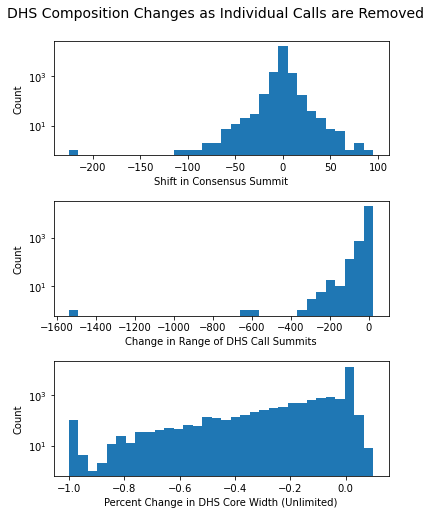

In [22]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(6,8))
# fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.4)
fig.patch.set_facecolor('white')

axes[0].hist(new_DHS_peak_all-original_DHS_peak_all, bins=32, align='left')
# axes[0].set_xlim([0, 400])
axes[0].set_xlabel('Shift in Consensus Summit')
axes[0].set_ylabel('Count')
axes[0].set_yscale('log')

axes[1].hist(new_DHS_peak_range_all-original_DHS_peak_range_all, bins=32, align='right')
# axes[1].set_xlim([0, 1])
axes[1].set_xlabel('Change in Range of DHS Call Summits')
axes[1].set_ylabel('Count')
axes[1].set_yscale('log')

axes[2].hist((new_unlimited_core_width_all-original_unlimited_core_width_all)/original_unlimited_core_width_all, bins=32)
axes[2].set_xlabel('Percent Change in DHS Core Width (Unlimited)')
axes[2].set_ylabel('Count')
axes[2].set_yscale('log')

plt.suptitle('DHS Composition Changes as Individual Calls are Removed', fontsize=14, x=0.5, y=0.94)

In [323]:
np.nanargmin((new_unlimited_core_width_all-original_unlimited_core_width_all)/original_unlimited_core_width_all)

/tmp/ipykernel_96657/1419570972.py:1: RuntimeWarning: invalid value encountered in true_divide
  np.nanargmin((new_unlimited_core_width_all-original_unlimited_core_width_all)/original_unlimited_core_width_all)


429

In [324]:
(new_unlimited_core_width_all-original_unlimited_core_width_all)[429]/original_unlimited_core_width_all[429]

-1.0

In [326]:
new_unlimited_core_width_all[429]

0

In [325]:
original_unlimited_core_width_all[429]

133

In [23]:
all_ln_nums = np.array(biosample_df['Altius Library ID'])
all_ln_stripped = np.array([])
for ln in all_ln_nums:
    if ln[-1].isalpha():
        all_ln_stripped = np.append(all_ln_stripped, ln[:-1])
    else:
        all_ln_stripped = np.append(all_ln_stripped, ln)

In [328]:
removed_call_nums_each_biosample_top100maxdistance[removed_call_nums_each_biosample_top100maxdistance>3]

array([8, 6, 5, 4])

In [327]:
biosample_df.loc[np.arange(733)[removed_call_nums_each_biosample_top100maxdistance>3]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
187,188,HAsp,NaN,ENCSR000ENB,ENCLB454ZZZ,ENCBS995OME,AG4073,LN3185,DS14794,DS14790,...,minElute,120.0,41.8,16800000.0,Buffer A,2010-05-06,32231827,0.4291,41041,40787
569,570,SJSA1,NaN,ENCSR620WAR,ENCLB925FNH,ENCBS327EZG,AG3978,LN20838A,DS24241A,DS24235A,...,Sucrose,120.0,50,8400000.0,PBS+A,2013-07-09,40853966,0.3684,53016,52024
715,716,DE,Primitive / embryonic,ENCSR166KPV,ENCLB393NTX,ENCBS088TSK,AG6944,LN43606A,DS55923A,DS39603C,...,NaN,NaN,1.1,540000.0,NaN,2017-01-05,457497776,0.5445,312848,307202
719,720,fBone_arm_left,NaN,ENCSR976XOY,ENCLB060BWD,ENCBS104ACH,AG7434,LN44780B,DS39408B,NaN,...,NaN,NaN,0.53,200000.0,A+Sucrose,NaN,198205332,0.4059,113852,110550


In [24]:
removed_call_nums_each_biosample_top100maxdistance = np.zeros(733, dtype=int)
for i in np.argsort(max_removed_distance_all)[-100:]:
    chunk = unique_removed_DHS_calls[i][0][-1]
    removed_lns = removed_ln_from_each_chunk[chunk]
    for ln in removed_lns:
        biosample_ind = np.where(all_ln_stripped==ln)[0][0]
        removed_call_nums_each_biosample_top100maxdistance[biosample_ind]+=1

Text(0.5, 1.0, 'Calls Removed from Each Biosample\nTop 100 Max Distance Cases')

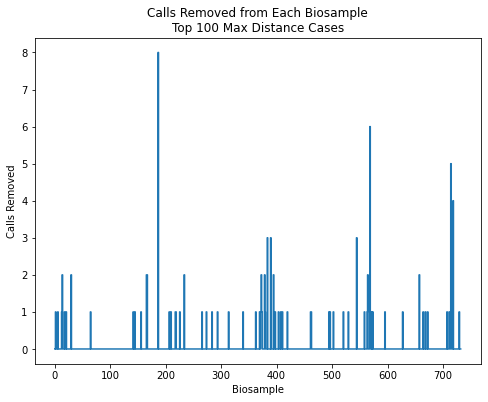

In [325]:
fig, axes = plt.subplots(figsize=(8,6))
fig.patch.set_facecolor('white')

axes.step(np.arange(733), removed_call_nums_each_biosample_top100maxdistance)
axes.set_xlabel('Biosample')
axes.set_ylabel('Calls Removed')
axes.set_title('Calls Removed from Each Biosample\nTop 100 Max Distance Cases')

Text(0.5, 1.0, 'Calls Removed from Each Biosample and DCC SPOT Scores\nTop 100 Max Distance Cases')

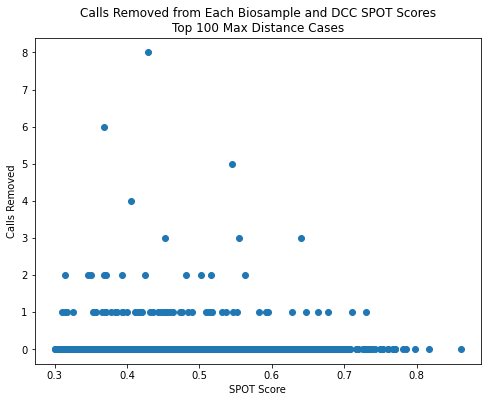

In [326]:
spot_scores = np.array(biosample_df['DCC SPOT score'])
fig, axes = plt.subplots(figsize=(8,6))
fig.patch.set_facecolor('white')

axes.scatter(spot_scores, removed_call_nums_each_biosample_top100maxdistance)

axes.set_xlabel('SPOT Score')
axes.set_ylabel('Calls Removed')
axes.set_title('Calls Removed from Each Biosample and DCC SPOT Scores\nTop 100 Max Distance Cases')

In [248]:
np.argsort(max_removed_distance_all)

array([ 9729, 11328,  2280, ..., 14214,  4701,  8085])

In [245]:
np.where(np.sort(max_removed_distance_all)>500)

(array([20470, 20471, 20472, 20473]),)

[5.]


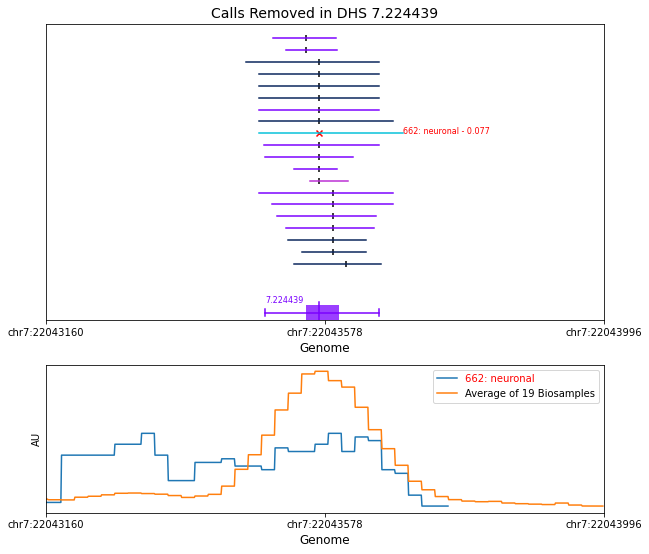

[83.33333333]


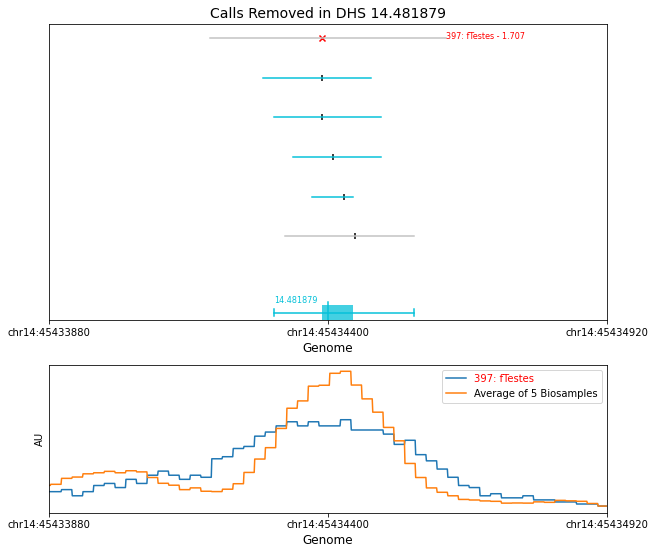

[78.48101266]


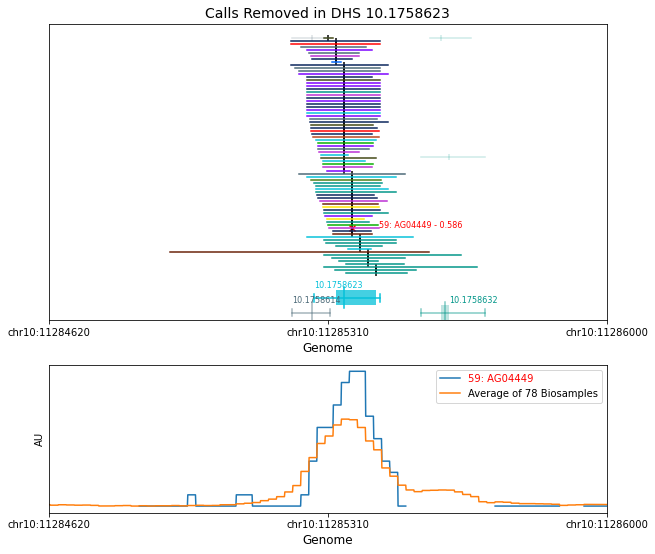

[25.]


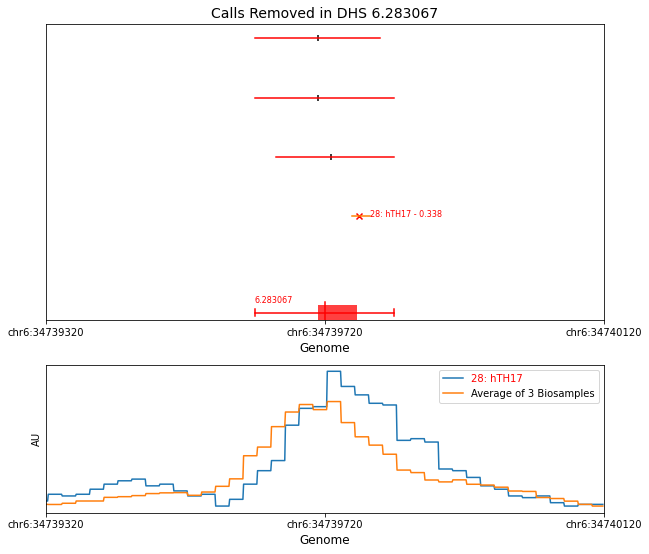

[90.90909091]


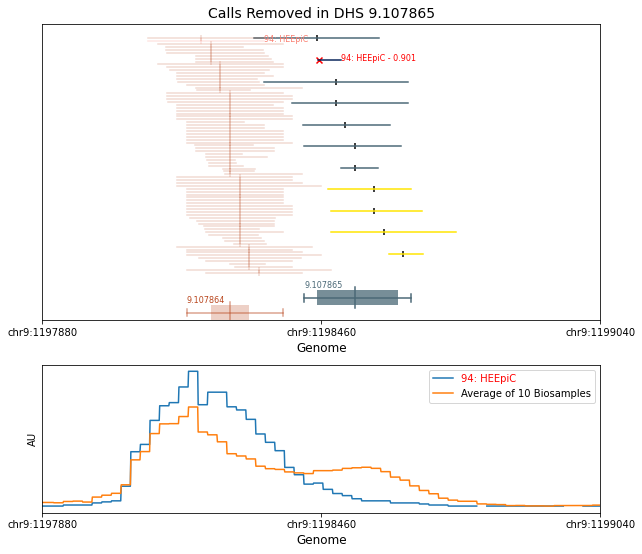

[95.71428571]


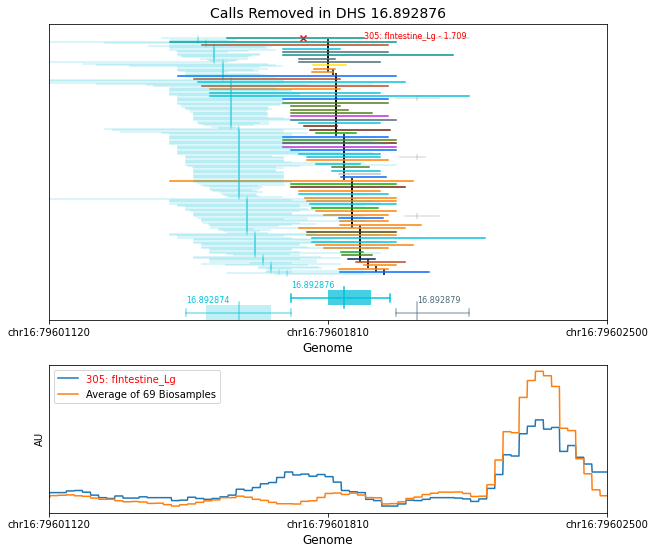

[100.]


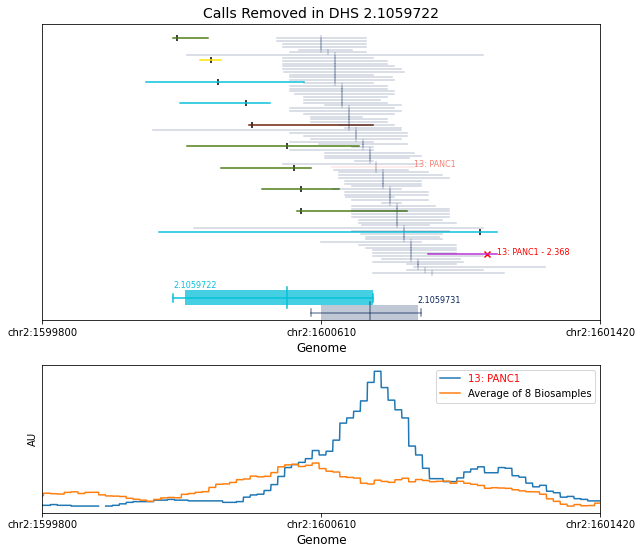

[100.]


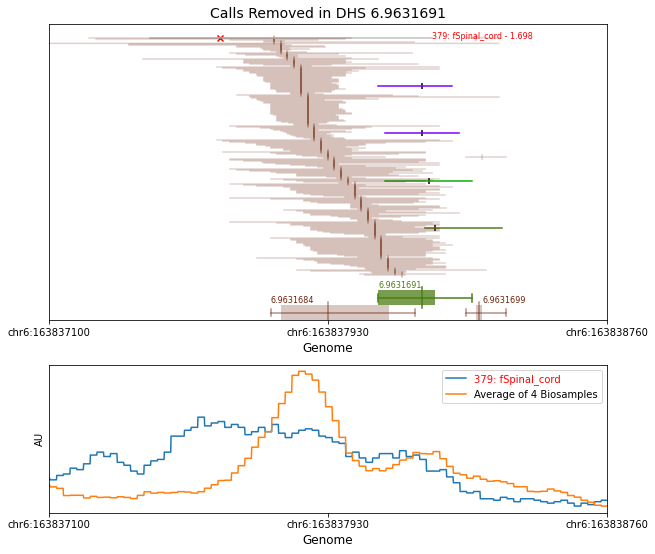

[45.45454545 81.81818182 22.72727273 40.90909091 54.54545455]


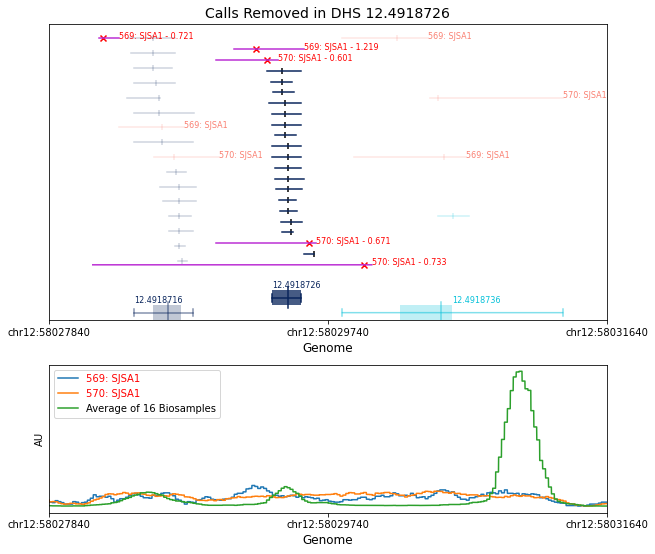

In [26]:
for i in np.argsort(max_removed_distance_all)[[0, 3500, 4044, 12747, 15849, 17860, 20471, 20472, 20473]]:
    plotting_removed_calls(i)

In [25]:
def plotting_removed_calls(i, unique_removed_DHS_calls=unique_removed_DHS_calls, removed_ln_from_each_chunk=removed_ln_from_each_chunk, buffer=300):
    dhs_calls = unique_removed_DHS_calls[i]
    chunk = dhs_calls[0][-1]
    chrm = dhs_calls[0][0]
    removed_lns = removed_ln_from_each_chunk[chunk]
    lns = dhs_calls[:, 3]
    scores = dhs_calls[:, 4].astype(float)
    mean_score = np.mean(scores)
    peaks = dhs_calls[:, 6].astype(int)
    starts = dhs_calls[:, 1].astype(int)
    # dhs_start = np.min(starts)
    ends = dhs_calls[:, 2].astype(int)
    # dhs_end = np.max(ends)
    # consensus_peak = np.median(peaks)
    # core_95 = np.percentile(peaks, [2.5, 97.5])


    #identifier/DHS of interest
    identifier = chunk2identifier[chunk]
    DHS_df = DHS_metadata[DHS_metadata['identifier']==identifier]
    DHS_ind = DHS_df.index[0]
    
    core_start = np.max([np.array(DHS_df['core_start']).astype(int)[0], 
                         np.array(DHS_df['start']).astype(int)[0]])
    core_end = np.min([np.array(DHS_df['core_end']).astype(int)[0], 
                       np.array(DHS_df['end']).astype(int)[0]])
    core_start_end = np.array([core_start, 
                               core_end])

    DHS_start_end = np.array([np.array(DHS_df['start']).astype(int)[0], 
                              np.array(DHS_df['end']).astype(int)[0]])

    DHS_peak = np.array(DHS_df['summit']).astype(int)[0]

    DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind]
    # DHS_top_comp_new = mixture_all_cycles_top_comp[1, DHS_ind]

    #DHS to right
    right_DHS_df = DHS_metadata.loc[[DHS_ind+1]]
    right_identifier = np.array(right_DHS_df['identifier'])[0]
    
    right_core_start = np.max([np.array(right_DHS_df['core_start']).astype(int)[0], 
                               np.array(right_DHS_df['start']).astype(int)[0]])
    right_core_end = np.min([np.array(right_DHS_df['core_end']).astype(int)[0], 
                             np.array(right_DHS_df['end']).astype(int)[0]])
    
    right_core_start_end = np.array([right_core_start, 
                                     right_core_end])
    right_DHS_start_end = np.array([np.array(right_DHS_df['start']).astype(int)[0], 
                                    np.array(right_DHS_df['end']).astype(int)[0]])
    right_DHS_peak = np.array(right_DHS_df['summit']).astype(int)[0]
    right_DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind+1]

    #DHS to left
    left_DHS_df = DHS_metadata.loc[[DHS_ind-1]]
    left_identifier = np.array(left_DHS_df['identifier'])[0]
    
    left_core_start = np.max([np.array(left_DHS_df['core_start']).astype(int)[0], 
                              np.array(left_DHS_df['start']).astype(int)[0]])
    left_core_end = np.min([np.array(left_DHS_df['core_end']).astype(int)[0], 
                            np.array(left_DHS_df['end']).astype(int)[0]])
    
    left_core_start_end = np.array([left_core_start, 
                                    left_core_end])
    left_DHS_start_end = np.array([np.array(left_DHS_df['start']).astype(int)[0], 
                                   np.array(left_DHS_df['end']).astype(int)[0]])
    left_DHS_peak = np.array(left_DHS_df['summit']).astype(int)[0]
    left_DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind-1]


    dhs_height = 0.05
    dhs_bot = 0

    #plotting
    fig, axes = plt.subplots(nrows=2, figsize=(10,9), gridspec_kw={'height_ratios': np.array([2, 1])})
    fig.patch.set_facecolor('white')

    right = False
#     right=True
    if ((right_DHS_start_end[0] < np.max(ends)) | right):
        right = True
        c = color[right_DHS_top_comp_original]
        adjustment = 0
        if right_core_start_end[1] - right_core_start_end[0] == 0:
            adjustment = 2
        right_dhs_rect = patches.Rectangle((right_core_start_end[0], dhs_bot),
                                            right_core_start_end[1] - right_core_start_end[0] + adjustment, 
                                            dhs_height,
                                            facecolor=c,
                                            alpha=0.25)
        axes[0].add_patch(right_dhs_rect)
        axes[0].text(right_core_start_end[1], dhs_bot + dhs_height + 0.01, right_identifier, fontsize=8, c=c)


        #plotting range of DHS
        axes[0].plot(np.arange(right_DHS_start_end[0], right_DHS_start_end[1] + 1), 
                     np.ones(right_DHS_start_end[1] - right_DHS_start_end[0] + 1)*(dhs_height / 2 + dhs_bot),
                     c=c,
                     alpha=0.5)
        axes[0].plot([right_DHS_start_end[0], right_DHS_start_end[0]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([right_DHS_start_end[1], right_DHS_start_end[1]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([right_DHS_peak, right_DHS_peak], 
                     [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                     c=c,
                     alpha=0.5)

    left = False
#     left=True
    if ((left_DHS_start_end[1] > np.min(starts)) | left):
        left = True
        c = color[left_DHS_top_comp_original]
        adjustment = 0
        if left_core_start_end[1] - left_core_start_end[0] == 0:
            adjustment = 2
        left_dhs_rect = patches.Rectangle((left_core_start_end[0], dhs_bot),
                                           left_core_start_end[1] - left_core_start_end[0] + adjustment, 
                                           dhs_height,
                                           facecolor=c,
                                           alpha=0.25)
        axes[0].add_patch(left_dhs_rect)
        axes[0].text(left_DHS_start_end[0], dhs_bot + dhs_height + 0.01, left_identifier, fontsize=8, c=c)

        #plotting range of DHS
        axes[0].plot(np.arange(left_DHS_start_end[0], left_DHS_start_end[1] + 1), 
                     np.ones(left_DHS_start_end[1] - left_DHS_start_end[0] + 1)*(dhs_height / 2 + dhs_bot),
                     c=c,
                     alpha=0.5)
        axes[0].plot([left_DHS_start_end[0], left_DHS_start_end[0]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([left_DHS_start_end[1], left_DHS_start_end[1]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([left_DHS_peak, left_DHS_peak], 
                     [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                     c=c,
                     alpha=0.5)


    c = color[DHS_top_comp_original]

    adjustment = 0
    if core_start_end[1] - core_start_end[0] == 0:
        adjustment = 2

    if (left | right):
        dhs_bot = 0.05

    dhs_rect = patches.Rectangle((core_start_end[0], dhs_bot),
                                  core_start_end[1] - core_start_end[0] + adjustment, 
                                  dhs_height,
                                  facecolor=c,
                                  alpha=0.75)
    axes[0].add_patch(dhs_rect)
    axes[0].text(DHS_start_end[0], dhs_bot + dhs_height + 0.01, identifier, fontsize=8, c=c)


    #plotting range of DHS
    axes[0].plot(np.arange(DHS_start_end[0], DHS_start_end[1] + 1), 
                 np.ones(DHS_start_end[1] - DHS_start_end[0] + 1)*(dhs_height / 2 + dhs_bot),
                 c=c)
    axes[0].plot([DHS_start_end[0], DHS_start_end[0]], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c)
    axes[0].plot([DHS_start_end[1], DHS_start_end[1]], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c)
    axes[0].plot([DHS_peak, DHS_peak], 
                 [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                 c=c)


    plt_start = np.min(starts)-buffer
    plt_end = np.max(ends)+buffer

    if right:
        plt_end = np.max([plt_end, right_DHS_start_end[1]+buffer])

    if left:
        plt_start = np.min([plt_start, left_DHS_start_end[0]-buffer])


    num_calls = len(peaks)
    used_biosamples_for_signal = []
    used_biosamples_for_average_signal = []
    average_signal_other_calls = np.array([])
    signal_at_peaks = []
    removed_peak_signals = []
    #plotting calls
    for ln, peak, start, end, ind, score in zip(lns, peaks, starts, ends, range(len(peaks)), scores):
        
        if ln in removed_lns:
            c = 'r'
            m = 'x'
        else:
            c = 'k'
            m = '|'
        biosample_ind = np.where(all_ln_stripped==ln)[0][0]
        agnum = biosample_df.loc[biosample_ind]['Altius Aggregation ID'][2:]
        filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + ln + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
#         if (left | right):
#             comp_color = c
#         else:
        comp_color = color[basis_all_cycles_top_comp[0, biosample_ind]]
        height = (0.95 - ((0.95 - 0.15) / num_calls * ind))
        axes[0].plot(np.arange(start, end + 1), 
                     np.ones(end - start + 1) * height,
                     c=comp_color)
        axes[0].scatter(peak, height, c=c, marker=m)
        
        if ln in removed_lns:
    #         print(biosample_ind)
            biosample_name = biosample_df.loc[biosample_ind]['Biosample name']
            x = end
            axes[0].text(x, height, str(biosample_ind) + ': ' + biosample_name + ' - ' + str(np.round(score, 3)), fontsize=8, c=c)
            if (str(biosample_ind) + ': ' + biosample_name) not in used_biosamples_for_signal:
                #plotting signal for biosamples
                #load bw file for biosample of interest
                read_in_question = bw_file.values(chrm, 
                                                  plt_start, 
                                                  plt_end, 
                                                  numpy=True)
                signal_to_plot = read_in_question
                signal_to_plot = ((signal_to_plot / np.nansum(signal_to_plot)) - 
                                 np.nanmin(signal_to_plot / np.nansum(signal_to_plot)))
                axes[1].plot(np.arange(plt_start, plt_end), signal_to_plot)
                used_biosamples_for_signal.append(str(biosample_ind) + ': ' + biosample_name)
#                 removed_peak_signals.append(read_in_question[peak-plt_start])
#                 signal_at_peaks.append(read_in_question[peak-plt_start])
        else:
#             if ind % 2 == 0:
#                 x = end
#             else:
#                 x = end
#             if score > mean_score:
#                 axes[0].text(x, height, str(np.round(score, 3)), fontsize=7, c=c) #maybe include biggest scores?
#             biosample_ind = np.where(all_ln_stripped==ln)[0][0]
#             comp_color = color[basis_all_cycles_top_comp[0, biosample_ind]]
            if biosample_ind not in used_biosamples_for_average_signal:
                used_biosamples_for_average_signal.append(biosample_ind)
                call_read = bw_file.values(chrm, 
                                           plt_start, 
                                           plt_end, 
                                           numpy=True)
#                 signal_at_peaks.append(call_read[peak-plt_start])
#                 #normalize signal per each biosample
#                 call_read = ((call_read / np.nansum(call_read)) - 
#                             np.nanmin(call_read / np.nansum(call_read)))
                
                if len(average_signal_other_calls) == 0:
                    average_signal_other_calls = np.append(average_signal_other_calls, call_read)
                else:
                    average_signal_other_calls = np.vstack((average_signal_other_calls, call_read))
        
        #signal at summit positions
        summit_signal_val = bw_file.values(chrm, 
                                           peak, 
                                           peak+1, 
                                           numpy=True)
        if ln in removed_lns:
            removed_peak_signals.append(summit_signal_val)
        signal_at_peaks.append(summit_signal_val)
        
        
        
    average_signal_to_plot = np.nanmean(average_signal_other_calls, axis=0)
    #normalize average signal
    average_signal_to_plot = ((average_signal_to_plot / np.nansum(average_signal_to_plot)) - 
                              np.nanmin(average_signal_to_plot / np.nansum(average_signal_to_plot)))
                              
    axes[1].plot(np.arange(plt_start, plt_end), 
                 average_signal_to_plot)
    
    removed_peak_signals = np.array(removed_peak_signals)
    signal_at_peaks = np.array(signal_at_peaks)
    removed_peak_signal_percentiles = []
    for removed_peak_signal in removed_peak_signals:
        percentile = percentileofscore(signal_at_peaks, removed_peak_signal)
        removed_peak_signal_percentiles.append(percentile)
    removed_peak_signal_percentiles = np.array(removed_peak_signal_percentiles)
    print(removed_peak_signal_percentiles)
    


    #nearby chunks
    chunks_to_plot = []
    if left:
        chunks_to_plot.append(-1)
    if right:
        chunks_to_plot.append(1)
    for shift in chunks_to_plot:
    #     if np.abs(shift)>1:

    #     nearby_colors = ['#0000FF', '#7393B3', '#89CFF0', '#088F8F']
        dhs = DHS_ind + shift
        comp = DHS_metadata.loc[dhs]['component']
        comp_color = color[np.where(np.array(comps_for_heatmap)==comp)[0][0]]
        nearby_identifier = DHS_metadata.loc[dhs]['identifier']
        nearby_chunk = identifier2chunk[nearby_identifier]
        nearby_core_chunk = nearby_chunk.split('_')[0]
        nearby_chunk_info = []
        core_bed = open("/net/seq/data/projects/ENCODE3_publications/erynes/ENCODEpaper2017/SubsetOf733/masterLists/workdir/peaks_all/"+nearby_core_chunk+".bed", "r")
        for line in core_bed:
            line = line.strip().split('\t')
            if line[-1]==nearby_chunk:
                nearby_chunk_info.append(line)
        nearby_chunk_info = np.array(nearby_chunk_info)
        num_calls = len(nearby_chunk_info)
        for read, ind in zip(nearby_chunk_info, range(len(nearby_chunk_info))):
            height = (0.95 - ((0.95 - 0.15) / num_calls * ind))
            c = color[np.where(np.array(comps_for_heatmap)==comp)[0][0]]
            if read[3] in removed_lns:
                c='#FA8072'
                biosample_ind = np.where(all_ln_stripped==read[3])[0][0]
                biosample_name = biosample_df.loc[biosample_ind]['Biosample name']
                axes[0].text(read[2].astype(int), height, str(biosample_ind) + ': ' + biosample_name, fontsize=8, c=c)
            axes[0].plot(np.arange(read[1].astype(int), read[2].astype(int) + 1), 
                         np.ones(read[2].astype(int) - read[1].astype(int) + 1) * height,
                         c=c,
                         alpha=0.2)
            axes[0].scatter(read[6].astype(int), height, c=c, marker='|', alpha=0.2)

    
    
    #range line 
    # axes.plot(np.a)

    axes[0].set_xlabel('Genome', fontsize=12)
    axes[0].set_xlim([plt_start, plt_end])
    axes[0].set_ylim([0, 1])
    axes[0].set_yticks([])
    axes[0].set_xticks([plt_start, int((plt_end+plt_start)/2), plt_end])
    axes[0].set_xticklabels([chrm + ':' + str(plt_start), chrm + ':' + str(int((plt_end+plt_start)/2)), chrm + ':' + str(plt_end)])

    axes[1].set_xlabel('Genome', fontsize=12)
    axes[1].set_xlim([plt_start, plt_end])
    axes[1].set_yticks([])
    axes[1].set_ylabel('AU')
    axes[1].set_xticks([plt_start, int((plt_end+plt_start)/2), plt_end])
    axes[1].set_xticklabels([chrm + ':' + str(plt_start), chrm + ':' + str(int((plt_end+plt_start)/2)), chrm + ':' + str(plt_end)])
    axes[1].legend(np.append(used_biosamples_for_signal, ['Average of %s Biosamples' %(len(used_biosamples_for_average_signal))]), 
                   labelcolor=np.append(np.array(['r']*len(used_biosamples_for_signal)), ['k']))
    axes[0].set_title('Calls Removed in DHS %s' %(identifier), fontsize=14)
    plt.show()
# plotting_removed_calls(0)

In [244]:
#biosamples in "Calls removed in DHS 6.283067" plot
biosample_df.loc[[616, 612, 613, 28]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
616,617,CD34_T6,Myeloid / erythroid,ENCSR564JUY,ENCLB947LFF,ENCBS986SUJ,AG3833,LN26288A,DS25730A,DS25729A,...,NaN,120.0,50,7500000.0,PBS+A,2014-01-15,407694757,0.5602,204374,203758
612,613,CD34_T4,Myeloid / erythroid,ENCSR148VUP,ENCLB809AHE,ENCBS721DUI,AG3831,LN26240A,DS25687A,DS24074A,...,NaN,80.0,50,7700000.0,PBS+A,2014-02-13,361402768,0.6173,245256,244793
613,614,CD34_T8,Myeloid / erythroid,ENCSR845CFB,ENCLB658VAX,ENCBS418LVC,AG3835,LN26258A,DS25769A,"DS25762A,DS24094A",...,NaN,80.0,30,7400000.0,PBS+A,2014-01-17,282261693,0.5385,167123,166835
28,29,hTH17,NaN,ENCSR000EQF,ENCLB597ZZZ,ENCBS364AAA,AG4198,LN2044,DS11039,NaN,...,microcon,80.0,8.5,NaN,NaN,2009-04-14,208484267,0.3505,73941,73856


In [28]:
#finding most isolated DHSs
ordered_removed_call_DHS_mindistances = []
for DHS in ordered_inds_removed_call_DHSs:
    dhs_df = DHS_metadata.loc[DHS-1:DHS+1]
    min_distance = np.min([(int(dhs_df.iloc[1]['start']) - int(dhs_df.iloc[0]['end'])), 
                           (int(dhs_df.iloc[2]['start']) - int(dhs_df.iloc[1]['end']))])
    ordered_removed_call_DHS_mindistances.append(min_distance)
ordered_removed_call_DHS_mindistances = np.array(ordered_removed_call_DHS_mindistances)

[100.]


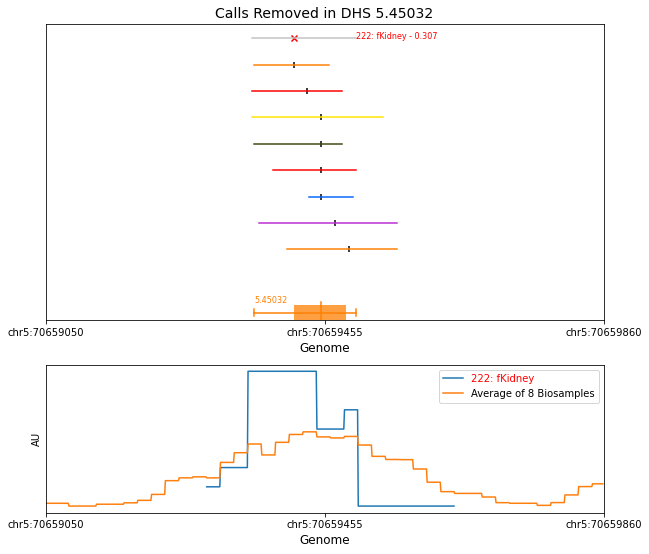

[66.66666667]


/tmp/ipykernel_80431/1252480773.py:275: RuntimeWarning: Mean of empty slice
  average_signal_to_plot = np.nanmean(average_signal_other_calls, axis=0)


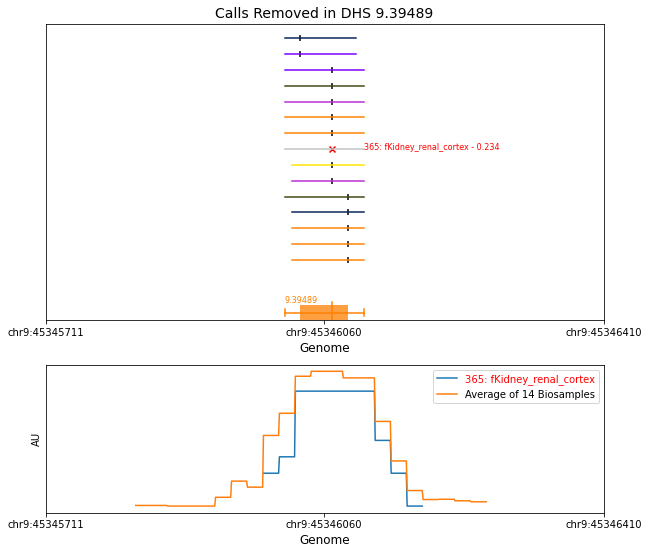

[98.24561404]


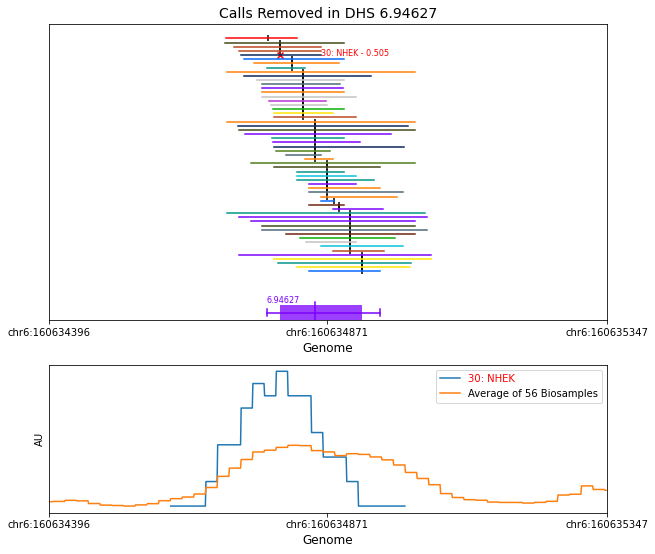

[100.]


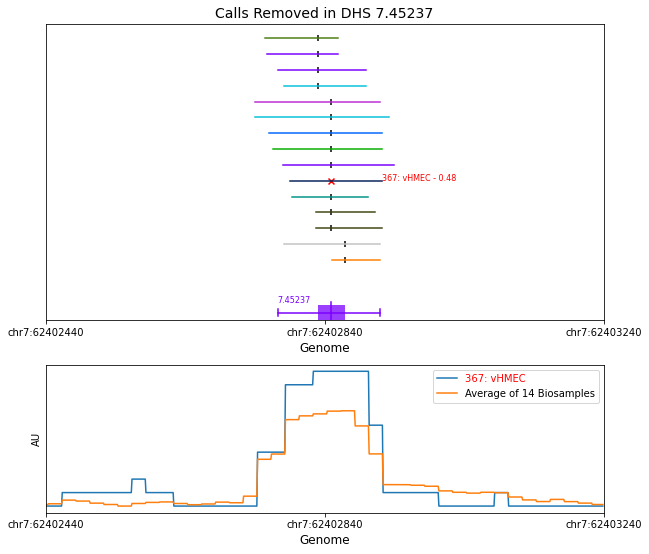

[40.]


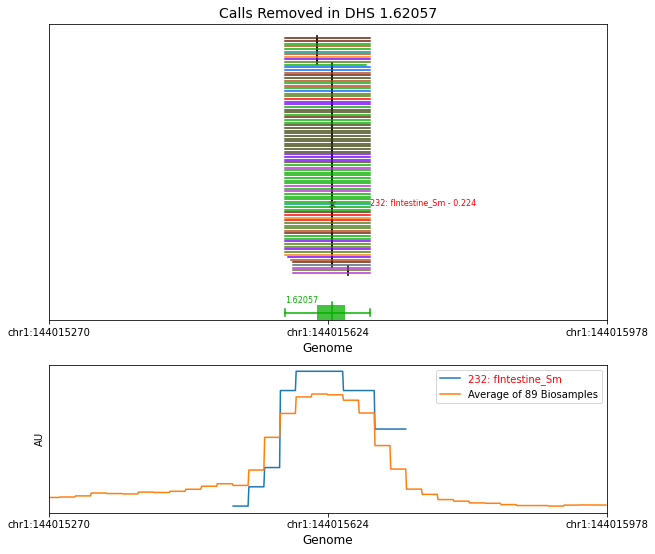

[64.70588235 63.02521008]


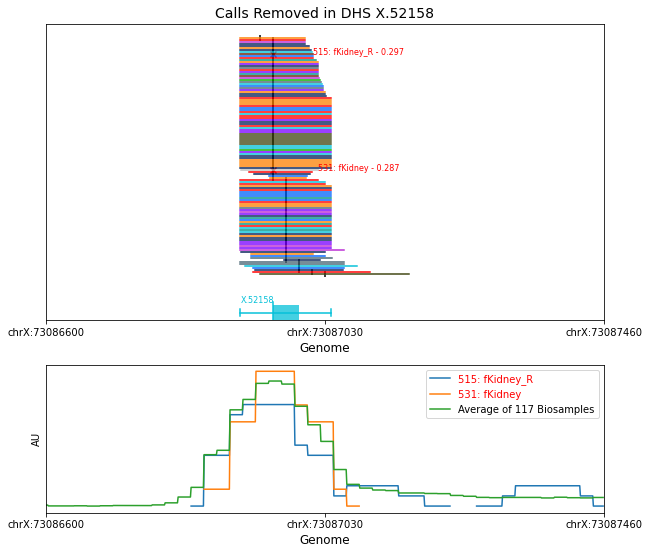

[100.]


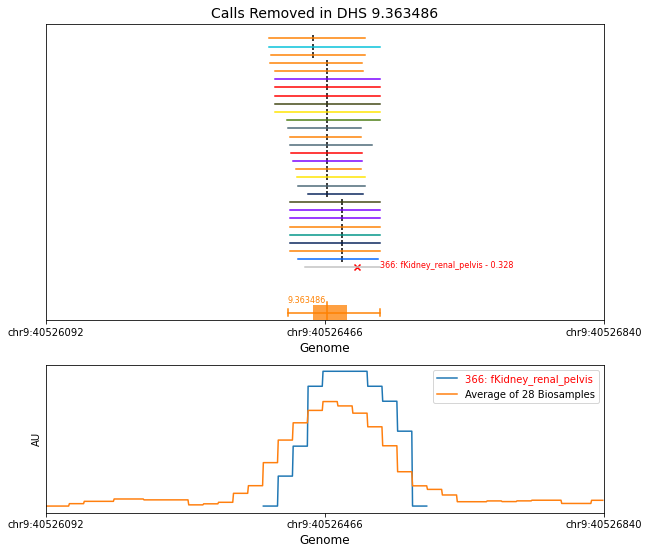

[87.80487805]


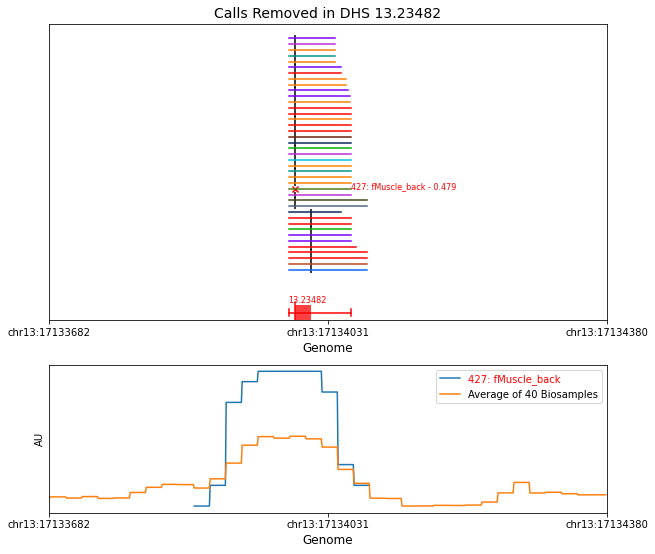

[10.34482759]


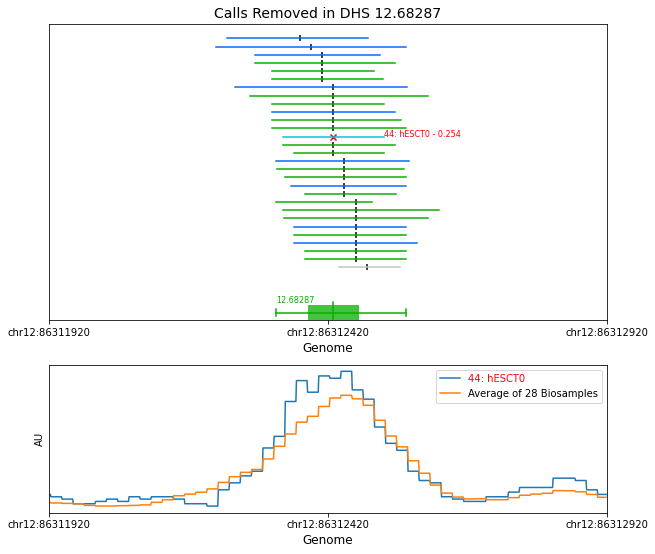

[53.33333333 66.66666667]


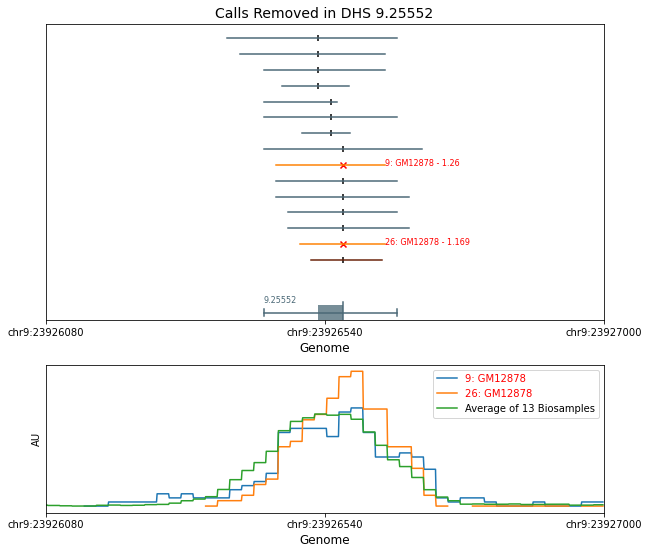

In [29]:
#most isolated DHSs with removed call
for i in np.argsort(-ordered_removed_call_DHS_mindistances)[:10]:
    plotting_removed_calls(i)

In [310]:
np.unique(np.array(biosample_df['Organ'], dtype='U40'))

array(['Adipose', 'Adrenal Gland', 'Amion', 'Blood', 'Bone', 'Brain',
       'Colon', 'Esophagus', 'Eye', 'Germ', 'Gonad', 'Gum', 'Heart',
       'Kidney', 'Large Intestine', 'Liver', 'Lung', 'Mammary',
       'Mesoderm', 'Muscle', 'Ovary', 'Pancreas', 'Periodontal Ligament',
       'Placenta', 'Pleura', 'Prostate', 'Pulmonary Artery', 'Skin',
       'Small Intestine', 'Spinal Cord', 'Spleen', 'Stomach', 'Stroma',
       'Tongue', 'Umbilical', 'Umbilical Cord', 'Uterus', 'Vascular',
       'nan'], dtype='<U40')

**Overlapping core regions**

In [39]:
core_start = np.array(DHS_metadata['core_start']).astype(float)
core_end = np.array(DHS_metadata['core_end']).astype(float)
chrm = np.array(DHS_metadata['seqname'])
identifiers = np.array(DHS_metadata['identifier'])
summit = np.array(DHS_metadata['summit']).astype(float)

start = np.array(DHS_metadata['start']).astype(float)
end = np.array(DHS_metadata['end']).astype(float)

start_right = start[1:]
end_right = end[1:]

start_adj = start[:-1]
end_adj = end[:-1]

core_start_right = core_start[1:]
core_end_right = core_end[1:]
chrm_right = chrm[1:]

core_start_adj = core_start[:-1]
core_end_adj = core_end[:-1]
chrm_adj = chrm[:-1]

In [40]:
core_start_lim = np.where(core_start < start, start, core_start)
core_end_lim = np.where(core_end > end, end, core_end)

right_start_lim = np.where(core_start_right < start_right, start_right, core_start_right)
adj_start_lim = np.where(core_start_adj < start_adj, start_adj, core_start_adj)

right_end_lim = np.where(core_end_right > end_right, end_right, core_end_right)
adj_end_lim = np.where(core_end_adj > end_adj, end_adj, core_end_adj)

In [42]:
# today = date.today()
# bed_path_name = os.path.join('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/', 'DHS_nonnan_core_start_end_CT' + today.strftime("%Y%m%d") + '.bed')
# f = open(bed_path_name, 'w')
# for i in range(len(chrm)):
#     if ((~np.isnan(core_start[i])) & (~np.isnan(core_end[i]))):
#         f.write(chrm[i] + '\t' + str(core_start[i].astype(int)) + '\t' + str(core_end[i].astype(int) + 1) + '\t' + str(identifiers[i]) + '\t' + str(i) + '\n')
# f.close()

In [43]:
# today = date.today()
# bed_path_name = os.path.join('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/', 'DHS_limited_nonnan_core_start_end_CT' + today.strftime("%Y%m%d") + '.bed')
# f = open(bed_path_name, 'w')
# for i in range(len(chrm)):
#     if ((~np.isnan(core_start_lim[i])) & (~np.isnan(core_end_lim[i]))):
#         f.write(chrm[i] + '\t' + str(core_start_lim[i].astype(int)) + '\t' + str(core_end_lim[i].astype(int) + 1) + '\t' + str(identifiers[i]) + '\t' + str(i) + '\n')
# f.close()

In [243]:
# today = date.today()
# bed_path_name = os.path.join('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/', 'DHS_summit_CT' + today.strftime("%Y%m%d") + '.bed')
# f = open(bed_path_name, 'w')
# for i in range(len(chrm)):
#     f.write(chrm[i] + '\t' + str(summit[i].astype(int)) + '\t' + str((summit[i]).astype(int) + 1) + '\t' + str(identifiers[i]) + '\t' + str(i) + '\n')
# f.close()

In [262]:
DHS_inds_summits_overlapping_cores = []
f = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/DHS_summits_with_overlapping_limited_core_regions_CT20220420.bed', 'r')
for line in f:
    line = re.split('\||\t|;', line.strip())
    if len(line) > 10:
        DHS_inds_summits_overlapping_cores.append(int(line[4]))
DHS_inds_summits_overlapping_cores = np.array(DHS_inds_summits_overlapping_cores)
DHS_inds_summits_overlapping_cores.shape

(7984,)

In [293]:
DHS_ind_pairs_fullcores_overlapping_fullcores = set([])
f = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/DHS_core_regions_overlapping_other_DHS_core_regions_CT20220420.bed', 'r')
for line in f:
    line = re.split('\||\t|;', line.strip())
    if ((len(line) > 10) & 
        (tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))) not in DHS_ind_pairs_fullcores_overlapping_fullcores)):
        
        DHS_ind_pairs_fullcores_overlapping_fullcores.add(tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))))
        
DHS_ind_pairs_fullcores_overlapping_fullcores = np.array(list(DHS_ind_pairs_fullcores_overlapping_fullcores))
DHS_ind_pairs_fullcores_overlapping_fullcores.shape

/tmp/ipykernel_184670/2232599042.py:10: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  DHS_ind_pairs_fullcores_overlapping_fullcores = np.array(list(DHS_ind_pairs_fullcores_overlapping_fullcores))


(13107,)

In [287]:
DHS_ind_pairs_cores_overlapping_cores = set([])
f = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/DHS_limited_core_regions_overlapping_other_DHS_limited_core_regions_CT20220420.bed', 'r')
for line in f:
    line = re.split('\||\t|;', line.strip())
    if ((len(line) > 10) & 
        (tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))) not in DHS_ind_pairs_cores_overlapping_cores)):
        
        DHS_ind_pairs_cores_overlapping_cores.add(tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))))
        
DHS_ind_pairs_cores_overlapping_cores = np.array(list(DHS_ind_pairs_cores_overlapping_cores))
DHS_ind_pairs_cores_overlapping_cores.shape

/tmp/ipykernel_184670/1638290964.py:10: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  DHS_ind_pairs_cores_overlapping_cores = np.array(list(DHS_ind_pairs_cores_overlapping_cores))


(10415,)

In [298]:
DHS_metadata.loc[np.arange(n_DHSs)[np.isnan(core_start)]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1135,chr1,1211280,1211559,1.1043523,0.220785,13,1211420,NaN,NaN,Lymphoid
3169,chr1,2176061,2176313,1.107863,3.406151,4,2176187,NaN,NaN,Primitive / embryonic
27066,chr1,16171725,16171947,1.1584519,0.565623,11,16171836,NaN,NaN,Digestive
28118,chr1,16896730,16896813,1.161098,2.244814,9,16896772,NaN,NaN,Digestive
30259,chr1,18109600,18109862,1.165412,0.519532,9,18109731,NaN,NaN,Primitive / embryonic
...,...,...,...,...,...,...,...,...,...,...
3488347,chrX,22086959,22087229,X.227406,0.407938,6,22087094,NaN,NaN,Musculoskeletal
3558875,chrX,124524028,124524199,X.818176,0.483490,7,124524114,NaN,NaN,Cancer / epithelial
3563959,chrX,131633400,131633499,X.859141,0.257480,5,131633450,NaN,NaN,Organ devel. / renal
3569687,chrX,137562841,137563120,X.893328,0.266131,12,137562980,NaN,NaN,Neural


In [207]:
summit_middle_4 = summit[4:-4]
chrm_middle_4 = chrm[4:-4]

core_start_lim_left4 = core_start_lim[:-8]
core_start_lim_left3 = core_start_lim[1:-7]
core_start_lim_left2 = core_start_lim[2:-6]
core_start_lim_left1 = core_start_lim[3:-5]
core_start_lim_right1 = core_start_lim[5:-3]
core_start_lim_right2 = core_start_lim[6:-2]
core_start_lim_right3 = core_start_lim[7:-1]
core_start_lim_right4 = core_start_lim[8:]


core_end_lim_left4 = core_end_lim[:-8]
core_end_lim_left3 = core_end_lim[1:-7]
core_end_lim_left2 = core_end_lim[2:-6]
core_end_lim_left1 = core_end_lim[3:-5]
core_end_lim_right1 = core_end_lim[5:-3]
core_end_lim_right2 = core_end_lim[6:-2]
core_end_lim_right3 = core_end_lim[7:-1]
core_end_lim_right4 = core_end_lim[8:]

chrm_left4 = chrm[:-8]
chrm_left3 = chrm[1:-7]
chrm_left2 = chrm[2:-6]
chrm_left1 = chrm[3:-5]
chrm_right1 = chrm[5:-3]
chrm_right2 = chrm[6:-2]
chrm_right3 = chrm[7:-1]
chrm_right4 = chrm[8:]

In [215]:
#checking to see how many summits overlap other core regions (max 4 DHSs away)
DHS_metadata.loc[np.arange(4, len(summit_middle_4)+4)[(((chrm_middle_4==chrm_left2) & 
                                                        (summit_middle_4 > core_start_lim_left2) & 
                                                        (summit_middle_4 < core_end_lim_left2)) | 
                                                       ((chrm_middle_4==chrm_left1) & 
                                                        (summit_middle_4 > core_start_lim_left1) & 
                                                        (summit_middle_4 < core_end_lim_left1)) | 
                                                       ((chrm_middle_4==chrm_right1) & 
                                                        (summit_middle_4 > core_start_lim_right1) & 
                                                        (summit_middle_4 < core_end_lim_right1)) | 
                                                       ((chrm_middle_4==chrm_right2) & 
                                                        (summit_middle_4 > core_start_lim_right2) & 
                                                        (summit_middle_4 < core_end_lim_right2)) |
                                                       ((chrm_middle_4==chrm_left4) & 
                                                        (summit_middle_4 > core_start_lim_left4) & 
                                                        (summit_middle_4 < core_end_lim_left4)) | 
                                                       ((chrm_middle_4==chrm_left3) & 
                                                        (summit_middle_4 > core_start_lim_left3) & 
                                                        (summit_middle_4 < core_end_lim_left3)) | 
                                                       ((chrm_middle_4==chrm_right3) & 
                                                        (summit_middle_4 > core_start_lim_right3) & 
                                                        (summit_middle_4 < core_end_lim_right3)) | 
                                                       ((chrm_middle_4==chrm_right4) & 
                                                        (summit_middle_4 > core_start_lim_right4) & 
                                                        (summit_middle_4 < core_end_lim_right4)))]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
46,chr1,629512,629580,1.1022629,27.972003,44,629550,629513,629550,Stromal B
764,chr1,1090148,1090320,1.10392,0.518168,10,1090220,1090190,1090306,Lymphoid
974,chr1,1163960,1164337,1.1041784,0.575266,14,1164190,1164003,1164284,Neural
1137,chr1,1212100,1212300,1.1043528,0.747310,7,1212170,1212170,1212224,Primitive / embryonic
1681,chr1,1441670,1441857,1.1051764,0.387490,27,1441770,1441683,1441817,Myeloid / erythroid
...,...,...,...,...,...,...,...,...,...,...
3588567,chrY,13751820,13752098,Y.316134,0.333116,34,13751960,13751890.0,13752054.0,Myeloid / erythroid
3588570,chrY,13753060,13753260,Y.316152,0.187982,13,13753130,13753090.0,13753198.0,Organ devel. / renal
3590242,chrY,18903620,18903779,Y.39718,0.180004,9,18903710,18903638.0,18903726.0,Neural
3590969,chrY,20565480,20565720,Y.42321,0.805730,5,20565590,20565552.0,20565610.0,Myeloid / erythroid


In [191]:
DHS_metadata.loc[[1679, 1680, 1681, 1682, 1683]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1679,chr1,1441220,1441400,1.1051753,0.408018,7,1441310,1441269,1441347,Stromal B
1680,chr1,1441360,1442060,1.1051759,0.365895,4,1441570,1441552,1441922,Musculoskeletal
1681,chr1,1441670,1441857,1.1051764,0.387490,27,1441770,1441683,1441817,Myeloid / erythroid
1682,chr1,1441980,1442220,1.105177,0.232820,4,1442150,1442112,1442207,Musculoskeletal
1683,chr1,1442168,1442400,1.1051775,0.203884,4,1442320,1442272,1442368,Musculoskeletal


In [29]:
#limited core overlaps
overlapping_lim_cores = DHS_metadata.loc[np.arange(len(chrm_adj))[((chrm_right==chrm_adj) & (right_start_lim < adj_end_lim) & (right_end_lim > adj_start_lim))]]
overlapping_lim_cores

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
46,chr1,629512,629580,1.1022629,27.972003,44,629550,629513,629550,Stromal B
312,chr1,917760,918220,1.103306,0.336283,9,917960,917850,918254,Neural
763,chr1,1089960,1090640,1.103922,0.230545,9,1090390,1090010,1090540,Primitive / embryonic
974,chr1,1163960,1164337,1.1041784,0.575266,14,1164190,1164003,1164284,Neural
1011,chr1,1173760,1173987,1.104235,1.656607,121,1173870,1173850,1173950,Organ devel. / renal
...,...,...,...,...,...,...,...,...,...,...
3588566,chrY,13751740,13752320,Y.31614,0.440083,7,13752170,13751816.0,13752210.0,Cardiac
3588569,chrY,13752960,13753460,Y.316158,0.198086,8,13753330,13753094.0,13753398.0,Primitive / embryonic
3590241,chrY,18903400,18903838,Y.39716,0.230867,4,18903530,18903530.0,18903770.0,Neural
3590968,chrY,20565320,20566420,Y.42323,0.340062,1,20565840,20565526.0,20566154.0,Myeloid / erythroid


In [30]:
DHS_metadata.loc[[305, 306]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
305,chr1,916200,916579,1.103294,0.320221,18,916430,916230,917060,Musculoskeletal
306,chr1,916660,916866,1.103296,1.408141,76,916770,916730,916810,Organ devel. / renal


In [31]:
np.where(np.arange(len(chrm_adj))[((chrm_right==chrm_adj) & (core_start_right < core_end_adj) & (core_end_right > core_end_adj))]==2936484-1)

(array([2752]),)

In [32]:
DHS_metadata.loc[[305, 306]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
305,chr1,916200,916579,1.103294,0.320221,18,916430,916230,917060,Musculoskeletal
306,chr1,916660,916866,1.103296,1.408141,76,916770,916730,916810,Organ devel. / renal


In [33]:
# DHS_metadata.loc[np.arange(len(chrm_adj))[((chrm_right==chrm_adj) & (core_start_right < core_end_adj) & (core_end_right > core_end_adj))]]

In [34]:
overlapping_cores = DHS_metadata.loc[np.arange(len(chrm_adj))[((chrm_right==chrm_adj) & (core_start_right < core_end_adj) & (core_end_right > core_start_adj))]]
overlapping_cores

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
46,chr1,629512,629580,1.1022629,27.972003,44,629550,629513,629550,Stromal B
305,chr1,916200,916579,1.103294,0.320221,18,916430,916230,917060,Musculoskeletal
312,chr1,917760,918220,1.103306,0.336283,9,917960,917850,918254,Neural
763,chr1,1089960,1090640,1.103922,0.230545,9,1090390,1090010,1090540,Primitive / embryonic
974,chr1,1163960,1164337,1.1041784,0.575266,14,1164190,1164003,1164284,Neural
...,...,...,...,...,...,...,...,...,...,...
3590724,chrY,19745700,19745955,Y.4105,0.301246,17,19745830,19745738.0,19746370.0,Neural
3590968,chrY,20565320,20566420,Y.42323,0.340062,1,20565840,20565526.0,20566154.0,Myeloid / erythroid
3591759,chrY,56833979,56834220,Y.993577,0.320516,18,56834070,56834050.0,56834326.0,Primitive / embryonic
3591781,chrY,56839100,56839640,Y.993698,0.209265,5,56839560,56839310.0,56839610.0,Digestive


In [35]:
overlapping_core_DHSs = set(np.array(overlapping_cores.index))
overlapping_core_DHSs_right = set(np.array(overlapping_cores.index)+1)

In [36]:
#how many times is a call removed from a dhs with overlapping core regions
remvoed_DHSs_overlapping_cores = []
for dhs in removed_DHS_inds:
    if ((dhs in overlapping_core_DHSs) | (dhs in overlapping_core_DHSs_right)):
        remvoed_DHSs_overlapping_cores.append(dhs)
remvoed_DHSs_overlapping_cores = np.array(remvoed_DHSs_overlapping_cores)
remvoed_DHSs_overlapping_cores_unique = np.unique(remvoed_DHSs_overlapping_cores)
print(remvoed_DHSs_overlapping_cores.shape)
print(remvoed_DHSs_overlapping_cores_unique.shape)

(208,)
(196,)


In [37]:
DHS_metadata.loc[np.where(np.isnan(core_end))]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1135,chr1,1211280,1211559,1.1043523,0.220785,13,1211420,NaN,NaN,Lymphoid
3169,chr1,2176061,2176313,1.107863,3.406151,4,2176187,NaN,NaN,Primitive / embryonic
27066,chr1,16171725,16171947,1.1584519,0.565623,11,16171836,NaN,NaN,Digestive
28118,chr1,16896730,16896813,1.161098,2.244814,9,16896772,NaN,NaN,Digestive
30259,chr1,18109600,18109862,1.165412,0.519532,9,18109731,NaN,NaN,Primitive / embryonic
...,...,...,...,...,...,...,...,...,...,...
3488347,chrX,22086959,22087229,X.227406,0.407938,6,22087094,NaN,NaN,Musculoskeletal
3558875,chrX,124524028,124524199,X.818176,0.483490,7,124524114,NaN,NaN,Cancer / epithelial
3563959,chrX,131633400,131633499,X.859141,0.257480,5,131633450,NaN,NaN,Organ devel. / renal
3569687,chrX,137562841,137563120,X.893328,0.266131,12,137562980,NaN,NaN,Neural


In [38]:
np.arange(len(core_start))[(core_start < start) | (core_end > end)]

array([     21,      23,      59, ..., 3591825, 3591826, 3591837])

In [39]:
extended_cores = DHS_metadata.loc[np.arange(len(core_start))[(core_start < start) | (core_end > end)]]
extended_cores

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
21,chr1,182681,182819,1.100658,0.090160,26,182740,182730,182825,Lymphoid
23,chr1,186817,186996,1.100665,0.084488,32,186910,186810,186934,Primitive / embryonic
59,chr1,632920,633140,1.1022733,6.444996,289,633030,632910,633110,Primitive / embryonic
65,chr1,634352,634540,1.1022781,48.741141,222,634430,634350,634550,Stromal A
108,chr1,817258,817403,1.1029632,2.194208,248,817330,817250,817350,Stromal A
...,...,...,...,...,...,...,...,...,...,...
3591806,chrY,56845380,56845580,Y.993811,0.228347,13,56845490,56845436.0,56845584.0,Digestive
3591822,chrY,56850075,56850420,Y.993929,0.202588,10,56850210,56850065.0,56850345.0,Digestive
3591825,chrY,56850880,56851260,Y.993951,0.278212,11,56851040,56850861.0,56851164.0,Primitive / embryonic
3591826,chrY,56851300,56851600,Y.993959,0.429361,19,56851450,56851290.0,56851590.0,Lymphoid


In [40]:
extended_core_DHSs = set(np.array(extended_cores.index))

In [41]:
#how many times is a call removed from a dhs with core region extended past start or end
removed_DHSs_extended_cores = []
for dhs in removed_DHS_inds:
    if dhs in extended_core_DHSs:
        removed_DHSs_extended_cores.append(dhs)
removed_DHSs_extended_cores = np.array(removed_DHSs_extended_cores)
removed_DHSs_extended_cores_unique = np.unique(removed_DHSs_extended_cores)
print(removed_DHSs_extended_cores.shape)
print(removed_DHSs_extended_cores_unique.shape)

(1665,)
(1466,)


**step by step resolving overlap examples**

In [42]:
file = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/chunk0700_partial_CT20220419.txt', "r")
step_data = []
all_steps = []
for line in file:
    line = (line.strip().split())
    if (line[0] == 'seqname'): #new step
        if step_data:
            all_steps.append(np.array(step_data))
        step_data = []
    else:
        step_data.append(line)
all_steps.append(np.array(step_data))

In [61]:
DHS_metadata['start'] = DHS_metadata['start'].astype(int)
DHS_metadata['end'] = DHS_metadata['end'].astype(int)

Text(0.5, 1.0, 'Step 1 of Isolated Peak Merging: Chunk0700_21_1 - Chunk0700_33_1')

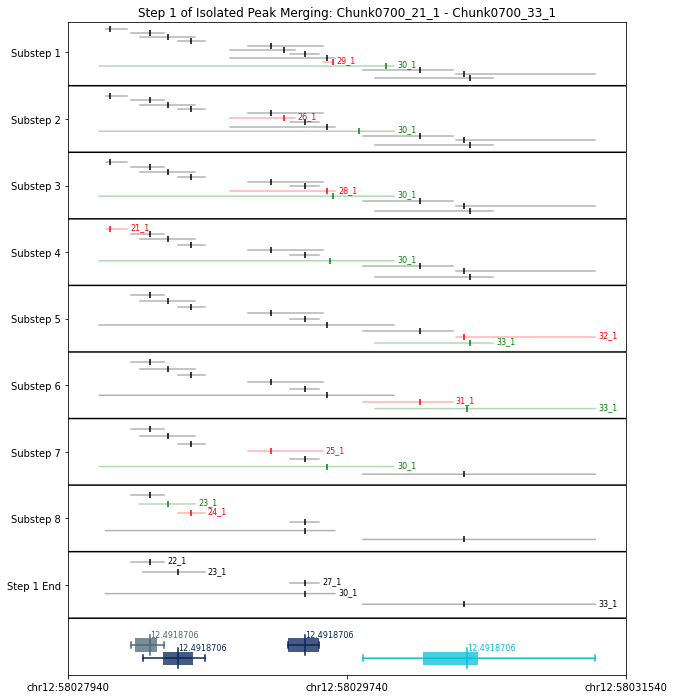

In [115]:
buffer=200
fig, axes = plt.subplots(nrows=1, figsize=(10,12))
fig.patch.set_facecolor('white')

start_height = 10
min_start = np.nan
max_end = np.nan

#plotting each line
for current_step, step_num in zip(all_steps, range(len(all_steps))):
    height = start_height - step_num
    min_start = np.nanmin([min_start, np.nanmin(current_step[:, 2].astype(int))])
    max_end = np.nanmax([max_end, np.nanmax(current_step[:, 3].astype(int))])
    if step_num < len(all_steps)-1:
        next_step = all_steps[step_num+1]
        current_rows = current_step[:, 0].astype(int)
        next_rows = next_step[:, 0].astype(int)
        missing_row = list(set(current_rows) - set(next_rows))[0]
        missing_row_ind = np.where(current_rows==(list(set(current_rows) - set(next_rows))))[0][0]
        current_numpeaks = current_step[np.where(current_step[:, 0]!=str(missing_row))[0], 7].astype(int)
        new_numpeaks = next_step[:, 7].astype(int)
        difference_numpeaks_ind = np.where(current_numpeaks-new_numpeaks!=0)[0][0]
        if difference_numpeaks_ind >= missing_row_ind:
            difference_numpeaks_ind += 1
        for row, ind in zip(current_step, range(len(current_step))):
            c = 'k'
            if ind == missing_row_ind:
                c = 'r'
                axes.text(row[3].astype(int)+20, height - 0.01, row[4], fontsize=8, c=c)
            if ind == difference_numpeaks_ind:
                c = 'g'
                axes.text(row[3].astype(int)+20, height - 0.01, row[4], fontsize=8, c=c)
            axes.plot(np.arange(int(row[2]), int(row[3]) + 1), 
                      np.ones(int(row[3]) - int(row[2]) + 1) * height,
                      c=c,
                      alpha=0.3)
            axes.scatter(int(row[9]), height, c=c, marker='|')
            height -= 0.8 / len(current_step)
    else:
        for row, ind in zip(current_step, range(len(current_step))):
            c = 'k'
            axes.plot(np.arange(int(row[2]), int(row[3]) + 1), 
                      np.ones(int(row[3]) - int(row[2]) + 1) * height,
                      c=c,
                      alpha=0.3)
            axes.scatter(int(row[9]), height, c=c, marker='|')
            axes.text(row[3].astype(int)+20, height - 0.01, row[4], fontsize=8, c=c)
            height -= 0.8 / len(current_step)

# minimum starting peak location 
min_start = int(min_start)
#maximum ending peak location
max_end = int(max_end)

# horizontal bars
for i in range(len(all_steps)):
    axes.plot(np.arange(min_start - buffer, max_end + 1 + buffer), 
              np.ones(max_end - min_start + 1 + (2 * buffer)) * (start_height - 0.85 - i),
              c='k')

dhss_of_interest = DHS_metadata[(DHS_metadata['start']>=min_start) & 
                                (DHS_metadata['end']<=max_end) & 
                                (DHS_metadata['seqname']=='chr12')]
starts = np.array(dhss_of_interest['start']).astype(int)
ends = np.array(dhss_of_interest['end']).astype(int)
core_starts = np.array(dhss_of_interest['core_start']).astype(int)
core_ends = np.array(dhss_of_interest['core_end']).astype(int)
summits = np.array(dhss_of_interest['summit']).astype(int)
comps = np.array(dhss_of_interest['component'])
identifiers = np.array(dhss_of_interest['identifier'])

for i in range(len(starts)-1):
    if i % 2 == 1:
        adjustment = 0.45
    else:
        adjustment = 0.65
    c = color[np.array(comps_for_heatmap)==comps[i]][0]
    if core_starts[i] < starts[i]:
        core_start = starts[i]
    else:
        core_start = core_starts[i]
    if core_ends[i] > ends[i]:
        core_end = ends[i]
    else:
        core_end = core_ends[i]
    dhs_rect = patches.Rectangle((core_start, 0 + adjustment),
                                  core_end - core_start, 
                                  0.2,
                                  facecolor=c,
                                  alpha=0.75)
    axes.add_patch(dhs_rect)
    axes.text(summits[i], 0.22 + adjustment, identifiers[0], fontsize=8, c=c)
    #plotting range of DHS
    axes.plot(np.arange(starts[i], ends[i] + 1), 
              np.ones(ends[i].astype(int) - starts[i].astype(int) + 1) * (0.1) + adjustment,
              c=c)
    axes.plot([starts[i].astype(int), starts[i].astype(int)], 
              [0.05 + adjustment, 0.15 + adjustment],
              c=c)
    axes.plot([ends[i].astype(int), ends[i].astype(int)], 
              [0.05 + adjustment, 0.15 + adjustment],
              c=c)
    axes.plot([summits[i].astype(int), summits[i].astype(int)], 
              [-0.05 + adjustment, 0.25 + adjustment],
              c=c)
axes.set_xlim([min_start-buffer, max_end+buffer])
axes.set_ylim([0.3, 10.1])
axes.set_yticks(np.flip(np.arange(1, 10)+0.65))
axes.set_yticklabels(['Substep 1', 'Substep 2', 'Substep 3', 'Substep 4', 'Substep 5', 'Substep 6', 'Substep 7',
                      'Substep 8', 'Step 1 End'])
chrm = 'chr12'
axes.set_xticks([min_start-buffer, int((max_end+min_start)/2), max_end+buffer])
axes.set_xticklabels([chrm + ':' + str(min_start-buffer), chrm + ':' + str(int((max_end+min_start)/2)), chrm + ':' + str(max_end+buffer)])
axes.set_title('Step 1 of Isolated Peak Merging: Chunk0700_21_1 - Chunk0700_33_1')

In [411]:
# fig, axes = plt.subplots(nrows=1, figsize=(12,6))
# fig.patch.set_facecolor('white')

# height = 2
# for step, step_num in zip(all_steps, range(len(all_steps))):
#     height -= 0.1
#     scores = step[:, 5].astype(float)
#     sorted_scores = np.sort(scores)
#     if len(sorted_scores) > step_num:
#         max_score_row = np.where(scores==sorted_scores[-(step_num + 1)])[0][0]
#         print(max_score_row)
#     for row, ind in zip(step, range(len(step))):
#         c = 'k'
#         if ((ind == max_score_row) & (len(sorted_scores) > step_num)):
#             c = 'r'
#         axes.plot(np.arange(int(row[2]), int(row[3]) + 1), 
#                   np.ones(int(row[3]) - int(row[2]) + 1) * height,
#                   c=c,
#                   alpha=0.3)
        
#         axes.scatter(int(row[9]), height, c=c, marker='|')
#         height -= 0.02

In [124]:
['row', 'seqname', 'start', 'end', 'ID', 'score', 'numsamples', 'numpeaks', 'width', 'summit', 'disp_low', 'disp_high']
['1', 'chr12', '58028180', '58028320', '21_1', '0.721320', '1', '1', '140', '58028210', '58028210', '58028210']